# 2 · Working capital around the world: receivable, inventory and payable days
The **cash conversion cycle** (CCC = receivable days + inventory days − payable days) is the number of days a firm's cash is tied up in operations. It reflects business models, bargaining power, legal systems and payment culture, and it is one of the first numbers a CFO or a lender looks at.

This notebook compares working capital across 70 countries and eight regions, follows it through 2008-09 and 2020, and tests whether firms with shorter cycles are more profitable, within firm, by region (as in Deloof, 2003).

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


In [2]:
D = ["dso", "dio", "dpo", "ccc"]
wc = aggregate.summary(p.assign(roa_pct=100 * p.roa), "loc", D + ["roa_pct"], min_firms=30).sort_values("ccc").rename(columns={"roa_pct": "ROA %"})
wc["region"] = p.groupby("loc")["region"].first().reindex(wc.index)
wc.round(1).to_csv(DATA / "working_capital_by_country.csv")
print("Median days by country (firms ≥ 30). Shortest and longest cash conversion cycles:")
pd.concat([wc.head(10), wc.tail(10)]).round(1)

Median days by country (firms ≥ 30). Shortest and longest cash conversion cycles:


,dso,dio,dpo,ccc,ROA %,firms,firm_years,region
loc,,,,,,,,
CAN,59.5,22.1,74.9,26.1,2.4,2521,19830,North America
AUS,72.3,10.4,64.4,46.9,-4.9,2319,24427,Other developed Asia-Pacific
HRV,74.4,47.6,76.5,49.9,2.3,85,1329,Other emerging
USA,51.9,32.0,42.5,50.0,4.1,11387,97555,North America
GBR,69.5,31.8,60.3,50.7,4.9,2658,26430,Western Europe
ESP,96.1,67.0,125.7,51.0,4.8,187,2462,Western Europe
NZL,53.4,44.7,50.2,53.9,6.2,194,2311,Other developed Asia-Pacific
ZAF,58.7,53.8,59.0,54.6,9.2,368,4667,Other emerging
BMU,63.5,17.5,38.4,55.1,4.5,85,934,Other emerging


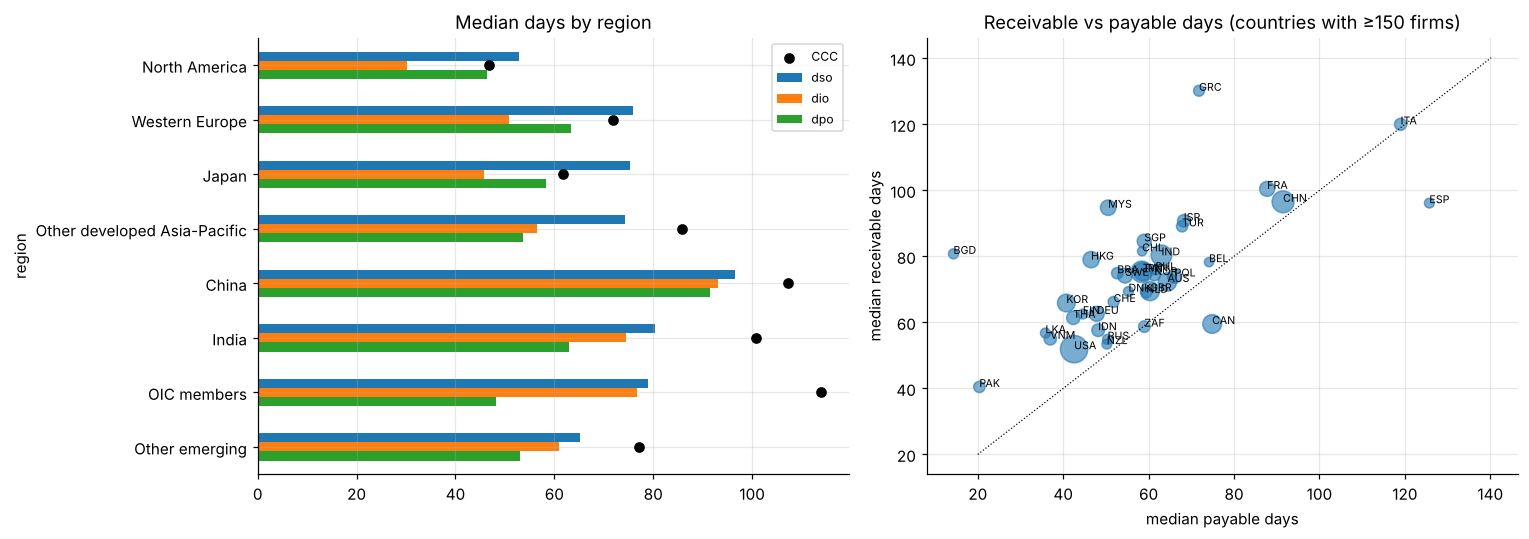

,dso,dio,dpo,ccc,ROA %,firms,firm_years
region,,,,,,,
North America,52.9,30.3,46.4,46.8,3.8,13908,117385
Western Europe,75.9,50.8,63.4,71.8,4.7,8453,94514
Japan,75.3,45.8,58.4,61.8,4.4,4261,58598
Other developed Asia-Pacific,74.3,56.5,53.6,85.8,3.1,9465,113375
China,96.5,93.2,91.5,107.3,5.4,4704,58149
India,80.3,74.5,63.0,100.7,5.9,3673,54194
OIC members,78.9,76.8,48.2,113.9,5.5,3511,48831
Other emerging,65.2,61.0,53.0,77.0,6.0,4817,62753


In [3]:
r = aggregate.summary(p.assign(roa_pct=100 * p.roa), "region", D + ["roa_pct"], min_firms=30).reindex(REG_ORDER).rename(columns={"roa_pct": "ROA %"})
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
r[["dso", "dio", "dpo"]].plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("Median days by region")
ax[0].scatter(r["ccc"], range(len(r)), color="k", zorder=3, label="CCC"); ax[0].legend(fontsize=8)
big = wc[wc.firms >= 150]
ax[1].scatter(big["dpo"], big["dso"], s=np.sqrt(big.firms) * 3, alpha=0.6)
for c, row in big.iterrows(): ax[1].annotate(c, (row.dpo, row.dso), fontsize=7)
lim = [20, max(big.dso.max(), big.dpo.max()) + 10]; ax[1].plot(lim, lim, "k:", lw=0.8)
ax[1].set_xlabel("median payable days"); ax[1].set_ylabel("median receivable days"); ax[1].set_title("Receivable vs payable days (countries with ≥150 firms)")
plt.tight_layout(); plt.savefig(IMG / "working_capital_regions.png", bbox_inches="tight"); plt.show()
r.round(1)

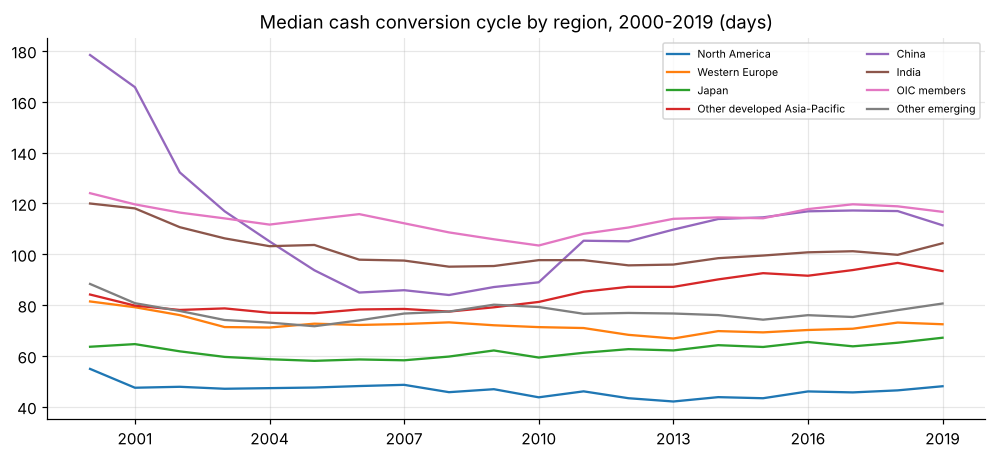

,CCC 2000,CCC 2019,change 2000→2019,same-firm change 2007→2009,same-firm change 2019→2020
region,,,,,
North America,54.9,48.1,-6.8,0.4,2.8
Western Europe,81.4,72.4,-9.0,-0.2,0.1
Japan,63.6,67.1,3.5,3.9,2.1
Other developed Asia-Pacific,84.1,93.4,9.2,-0.7,0.8
China,178.4,111.4,-67.0,-4.1,-0.8
India,119.9,104.3,-15.6,-1.2,-8.2
OIC members,124.0,116.7,-7.3,0.0,3.5
Other emerging,88.3,80.6,-7.7,2.5,1.4


In [4]:
ty = p[p.fyear <= 2019].groupby(["fyear", "region"])["ccc"].median().unstack()[REG_ORDER]
cy = aggregate.summary(p, ["loc", "fyear"], D, min_firms=20).round(1); cy.to_csv(DATA / "working_capital_by_country_year.csv")
fig, ax = plt.subplots(figsize=(11, 4.5)); ty.plot(ax=ax); ax.set_title("Median cash conversion cycle by region, 2000-2019 (days)"); ax.legend(fontsize=7, ncol=2); int_years(ax)
plt.savefig(IMG / "ccc_trends.png", bbox_inches="tight"); plt.show()
chg = (ty.loc[2019] - ty.loc[2000]).rename("change 2000→2019 (days)")
# shocks: same-firm change in CCC, firms observed in both years
def same_firm_change(y0, y1):
    a = p[p.fyear == y0].set_index("gvkey"); b = p[p.fyear == y1].set_index("gvkey"); j = a.index.intersection(b.index)
    d = (b.loc[j, "ccc"] - a.loc[j, "ccc"]).groupby(a.loc[j, "region"]).median()
    return d
pd.DataFrame({"CCC 2000": ty.loc[2000], "CCC 2019": ty.loc[2019], "change 2000→2019": chg,
              "same-firm change 2007→2009": same_firm_change(2007, 2009), "same-firm change 2019→2020": same_firm_change(2019, 2020)}).reindex(REG_ORDER).round(1)

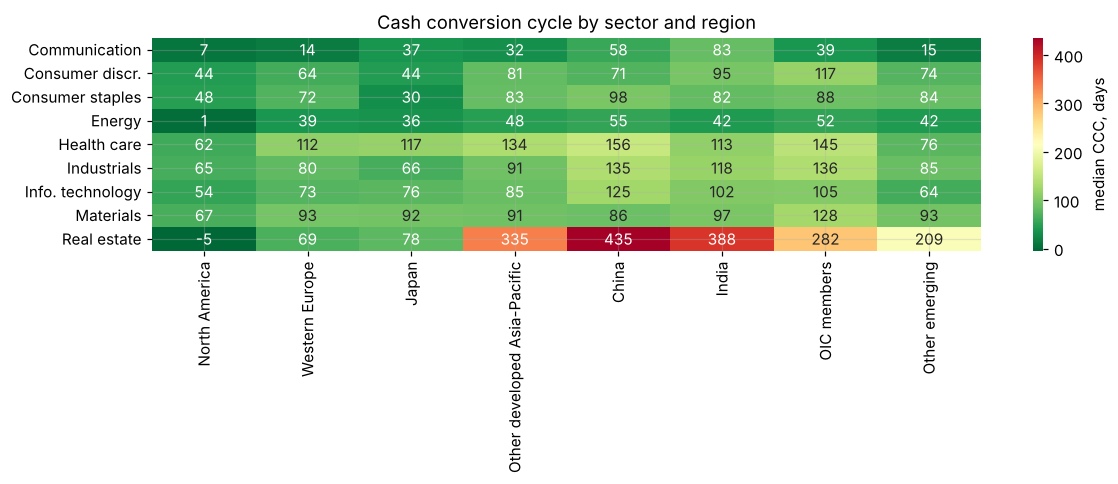

In [5]:
sec_names = {10: "Energy", 15: "Materials", 20: "Industrials", 25: "Consumer discr.", 30: "Consumer staples", 35: "Health care",
             45: "Info. technology", 50: "Communication", 60: "Real estate"}
s = p.assign(sector=p.gsector.map(sec_names)).groupby(["sector", "region"])["ccc"].median().unstack()[REG_ORDER]
fig, ax = plt.subplots(figsize=(11, 4.5)); sns.heatmap(s, annot=True, fmt=".0f", cmap="RdYlGn_r", ax=ax, cbar_kws={"label": "median CCC, days"})
ax.set_title("Cash conversion cycle by sector and region"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(IMG / "ccc_sector_region.png", bbox_inches="tight"); plt.show()

## Does a shorter cycle mean higher profitability?
Within-firm regressions (firm and year fixed effects, standard errors clustered by firm) of operating ROA on each working-capital component, with size, sales growth and leverage as controls, estimated separately by region. Each component is scaled to 100 days, so the coefficient is the change in ROA (in percentage points) for 100 more days.

In [6]:
q = p.assign(**{f"{c}_100": p[c] / 100 for c in D}, roa_pct=100 * p["roa"])
rows = []
for reg_ in REG_ORDER:
    sub = q[q.region == reg_]
    for comp in ["ccc", "dso", "dio", "dpo"]:
        res = regress.fe(sub, "roa_pct", [f"{comp}_100", "size", "sales_growth", "leverage"])
        if res is not None:
            rows.append({"region": reg_, "component (per 100 days)": comp.upper(), "coef (ROA pts)": res.loc[f"{comp}_100", "coef"],
                         "t": res.loc[f"{comp}_100", "t"], "firm-years": res.attrs["nobs"], "firms": res.attrs["firms"]})
fe = pd.DataFrame(rows)
fe.round(3).to_csv(DATA / "ccc_profitability_fe.csv", index=False)
fe.pivot(index="region", columns="component (per 100 days)", values="coef (ROA pts)").reindex(REG_ORDER).round(2)

component (per 100 days),CCC,DIO,DPO,DSO
region,,,,
North America,-0.00,-0.51,-0.22,-0.32
Western Europe,-0.17,-0.48,-0.22,-0.50
Japan,-0.08,-0.24,-0.06,-0.22
Other developed Asia-Pacific,-0.23,-0.20,0.10,-0.17
China,-0.14,-0.16,-0.46,-0.71
India,-0.06,-0.09,-0.18,-0.15
OIC members,-0.01,-0.07,-0.26,-0.19
Other emerging,-0.01,0.14,-0.22,-0.33


In [7]:
fe.pivot(index="region", columns="component (per 100 days)", values="t").reindex(REG_ORDER).round(1).rename_axis("t-statistics")

component (per 100 days),CCC,DIO,DPO,DSO
t-statistics,,,,
North America,-0.1,-2.5,-2.1,-2.9
Western Europe,-2.8,-3.5,-3.4,-6.0
Japan,-0.4,-1.0,-0.4,-0.9
Other developed Asia-Pacific,-5.2,-2.8,1.4,-2.7
China,-3.1,-2.3,-5.9,-8.3
India,-2.1,-1.8,-4.9,-5.2
OIC members,-0.3,-1.2,-3.2,-3.2
Other emerging,-0.2,1.6,-2.6,-4.6


## Findings
* **North American firms run the leanest working capital.** Their median cash conversion cycle is 47 days (receivables 53, inventory 30, payables 46). It is 62 days in Japan, 72 in Western Europe, about 100 in India and China, and 114 in OIC countries. Canada (26 days), Australia, Croatia, the USA and the UK have the shortest cycles among countries; Bangladesh (203 days), Latvia, Morocco, Tunisia and Saudi Arabia the longest.
* **The gap comes from inventory and supplier credit, not only from customers.** OIC firms collect from customers about as slowly as European ones (79 vs 76 days) but hold far more inventory (77 vs 51 days) and get much less credit from suppliers (48 vs 63 days). Chinese firms both give and take long credit (97 and 92 days). Bangladesh is extreme: firms pay suppliers in 14 days but hold inventory for 141.
* **Long-run convergence:** China's median cycle fell from 178 days in 2000 to 111 in 2019 (partly a change in sample composition), India's from 120 to 104, and North America's from 55 to 48. Japan and the other developed Asia-Pacific markets moved the other way.
* **Crises barely moved the median firm.** The same-firm change in the cycle from 2007 to 2009 was within ±4 days in every region. From 2019 to 2020 it was within ±4 days except India (-8). The adjustment came through sales and inventories together, not through a collapse in trade credit.
* **Sector matters more than country in most places:** real estate (developers carry unsold property as inventory) and health care have the longest cycles, energy and communication services the shortest. Real-estate cycles above 300 days in China, India and Asia-Pacific reflect property development models.
* **Shorter cycles go with higher profitability within firms.** In firm and year fixed-effects regressions, 100 more receivable days lower operating ROA by 0.2-0.7 percentage points in every region (t up to -8). Longer payables also go with *lower* ROA, as Deloof (2003) found: less profitable firms wait longer to pay. The effects are economically modest, so working-capital release matters mainly for cash, not for margins.